# License Plate Detection and OCR Experiments - Multi-Frame Quality Diagnosis

This notebook do the experiment: **first determine whether the video contains usable plate detail**, then run OCR on a small set of quality-ranked crops from distinct frames.

- Uses the already-trained YOLO plate detector.
- Reads the original video without modifying or re-encoding it.
- Crops are derived experimental images; the source video remains unchanged.
- Quality scores rank candidates; they do not prove that characters are readable.
- Never turn a low-confidence guess into a plate number. Preserve unreadable/conflicting results.

In [1]:
from pathlib import Path
import re, time, warnings
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ultralytics import YOLO
from paddleocr import PaddleOCR
import easyocr
warnings.filterwarnings("ignore")

PLATE_MODEL_PATH = Path("../models/alpr_26n.pt")
VIDEO_PATH = Path("../data/raw/video.mp4")
OUTPUT_DIR = Path("outputs")
CROPS_DIR = OUTPUT_DIR / "ranked_crops"
OUTPUT_DIR.mkdir(exist_ok=True)
CROPS_DIR.mkdir(exist_ok=True)

assert PLATE_MODEL_PATH.is_file(), f"Missing trained YOLO weights: {PLATE_MODEL_PATH}"
assert VIDEO_PATH.is_file(), f"Missing authorized test video: {VIDEO_PATH}"

plate_detector = YOLO(str(PLATE_MODEL_PATH))
print("Detector classes:", plate_detector.names)

Detector classes: {0: 'License_Plate'}


## Configure a short video interval and inspect the source

Start with a short interval containing the motorcycle of interest. If know an approximate timestamp, set `START_SECONDS`. The notebook samples frames at a fixed interval and runs the existing plate detector on each sampled full frame.

In [2]:
START_SECONDS = 0.0       # Set near the motorcycle's appearance
END_SECONDS = None        # None means continue to the end of the video
SAMPLE_EVERY_SECONDS = 0.20
DETECTOR_CONFIDENCE = 0.20
MAX_DETECTIONS_PER_FRAME = 10

cap = cv2.VideoCapture(str(VIDEO_PATH))
assert cap.isOpened(), "Could not open video"

fps = cap.get(cv2.CAP_PROP_FPS) or 0
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
duration = frame_count / fps if fps > 0 else None

print({"width": width, "height": height, "fps": fps, "frames": frame_count, "duration_seconds": duration})

if END_SECONDS is None: END_SECONDS = duration

assert fps > 0 and END_SECONDS is not None, "Video FPS/duration unavailable; inspect the file first"
assert 0 <= START_SECONDS < END_SECONDS <= duration

sample_times = np.arange(START_SECONDS, END_SECONDS, SAMPLE_EVERY_SECONDS)
print(f"Sampling {len(sample_times)} timestamps")

{'width': 2568, 'height': 1440, 'fps': 30.0, 'frames': 950, 'duration_seconds': 31.666666666666668}
Sampling 159 timestamps


## Detect plates and measure crop quality across frames

Each candidate stores the frame/time, detector confidence, crop dimensions, grayscale brightness/contrast, Laplacian variance (a rough sharpness indicator), and edge density. These simple measurements are not a universal image-quality score; inspect the gallery before deciding which crops are useful.

In [3]:
def crop_quality(crop):
    gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY) if crop.ndim == 3 else crop
    
    return {
        "crop_width": int(gray.shape[1]),
        "crop_height": int(gray.shape[0]),
        "mean_brightness": float(np.mean(gray)),
        "contrast_std": float(np.std(gray)),
        "laplacian_variance": float(cv2.Laplacian(gray, cv2.CV_64F).var()),
        "edge_density": float(np.mean(cv2.Canny(gray, 80, 160) > 0)),
    }

candidates = []
for frame_number, timestamp in enumerate(sample_times):
    cap.set(cv2.CAP_PROP_POS_MSEC, float(timestamp * 1000))
    ok, frame = cap.read()
    
    if not ok: continue
    
    pred = plate_detector.predict(frame, conf=DETECTOR_CONFIDENCE, verbose=False)[0]
    
    if pred.boxes is None: continue
    
    boxes = pred.boxes.xyxy.cpu().numpy()
    confs = pred.boxes.conf.cpu().numpy()
    for det_index, (box, det_conf) in enumerate(zip(boxes[:MAX_DETECTIONS_PER_FRAME], confs[:MAX_DETECTIONS_PER_FRAME])):
        x1,y1,x2,y2 = np.round(box).astype(int)
        pad_x = max(2, int((x2-x1)*0.08)); pad_y = max(2, int((y2-y1)*0.12))
        x1=max(0,x1-pad_x); y1=max(0,y1-pad_y); x2=min(width,x2+pad_x); y2=min(height,y2+pad_y)
        crop = frame[y1:y2, x1:x2].copy()
        
        if crop.size == 0: continue
        
        name=f"frame_{int(round(timestamp*1000)):09d}_det_{det_index}.jpg"
        crop_path=CROPS_DIR/name
        cv2.imwrite(str(crop_path), crop)
        
        row={"frame_number":int(round(timestamp*fps)),"timestamp_seconds":float(timestamp),
             "detection_index":det_index,"detector_confidence":float(det_conf),
             "crop_path":str(crop_path),**crop_quality(crop)}
        candidates.append(row)

cap.release()
candidates_df=pd.DataFrame(candidates)

assert len(candidates_df), "No plates detected in this interval. Try another timestamp or check the detector/model class."
display(candidates_df.head())
print("Candidate crops:",len(candidates_df),"Distinct sampled frames:",candidates_df.frame_number.nunique())

,frame_number,timestamp_seconds,detection_index,detector_confidence,crop_path,crop_width,crop_height,mean_brightness,contrast_std,laplacian_variance,edge_density
0,0,0.0,0,0.654059,outputs\ranked_crops\frame_000000000_det_0.jpg,104,77,136.633616,63.262307,159.807050,0.112013
1,6,0.2,0,0.654636,outputs\ranked_crops\frame_000000200_det_0.jpg,104,78,137.039571,62.989139,161.936691,0.107742
2,12,0.4,0,0.644546,outputs\ranked_crops\frame_000000400_det_0.jpg,104,79,137.119645,62.737981,165.140947,0.108082
3,18,0.6,0,0.628930,outputs\ranked_crops\frame_000000600_det_0.jpg,103,78,137.923575,63.190785,169.248710,0.111028
4,24,0.8,0,0.609775,outputs\ranked_crops\frame_000000800_det_0.jpg,99,78,138.869723,63.804071,168.313935,0.111370


Candidate crops: 250 Distinct sampled frames: 155


## Visualize crop quality and inspect the candidates

The ranking below is deliberately simple: prioritize larger crops and sharpness, while showing the raw measurements. It is only a way to select candidates for human inspection-not an OCR confidence estimate.

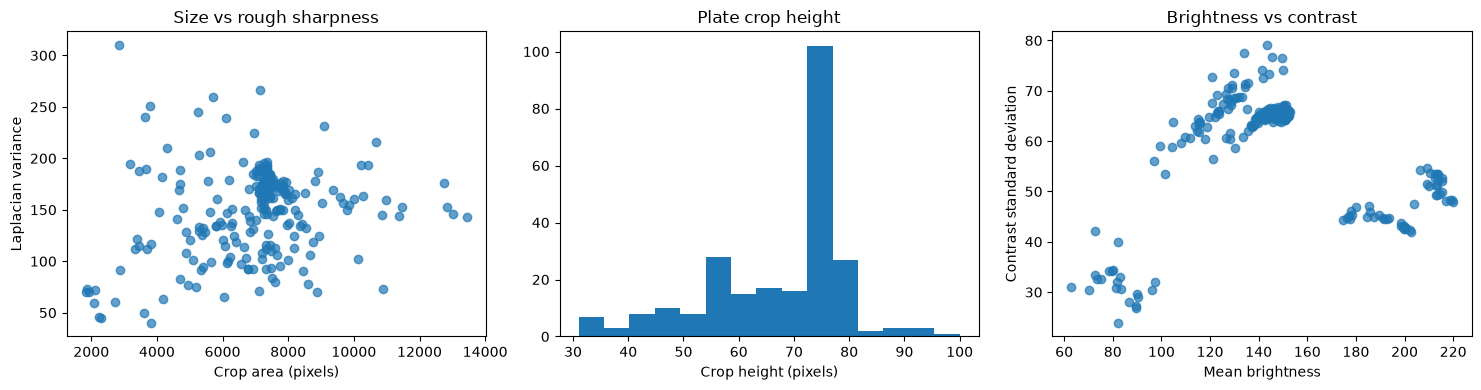

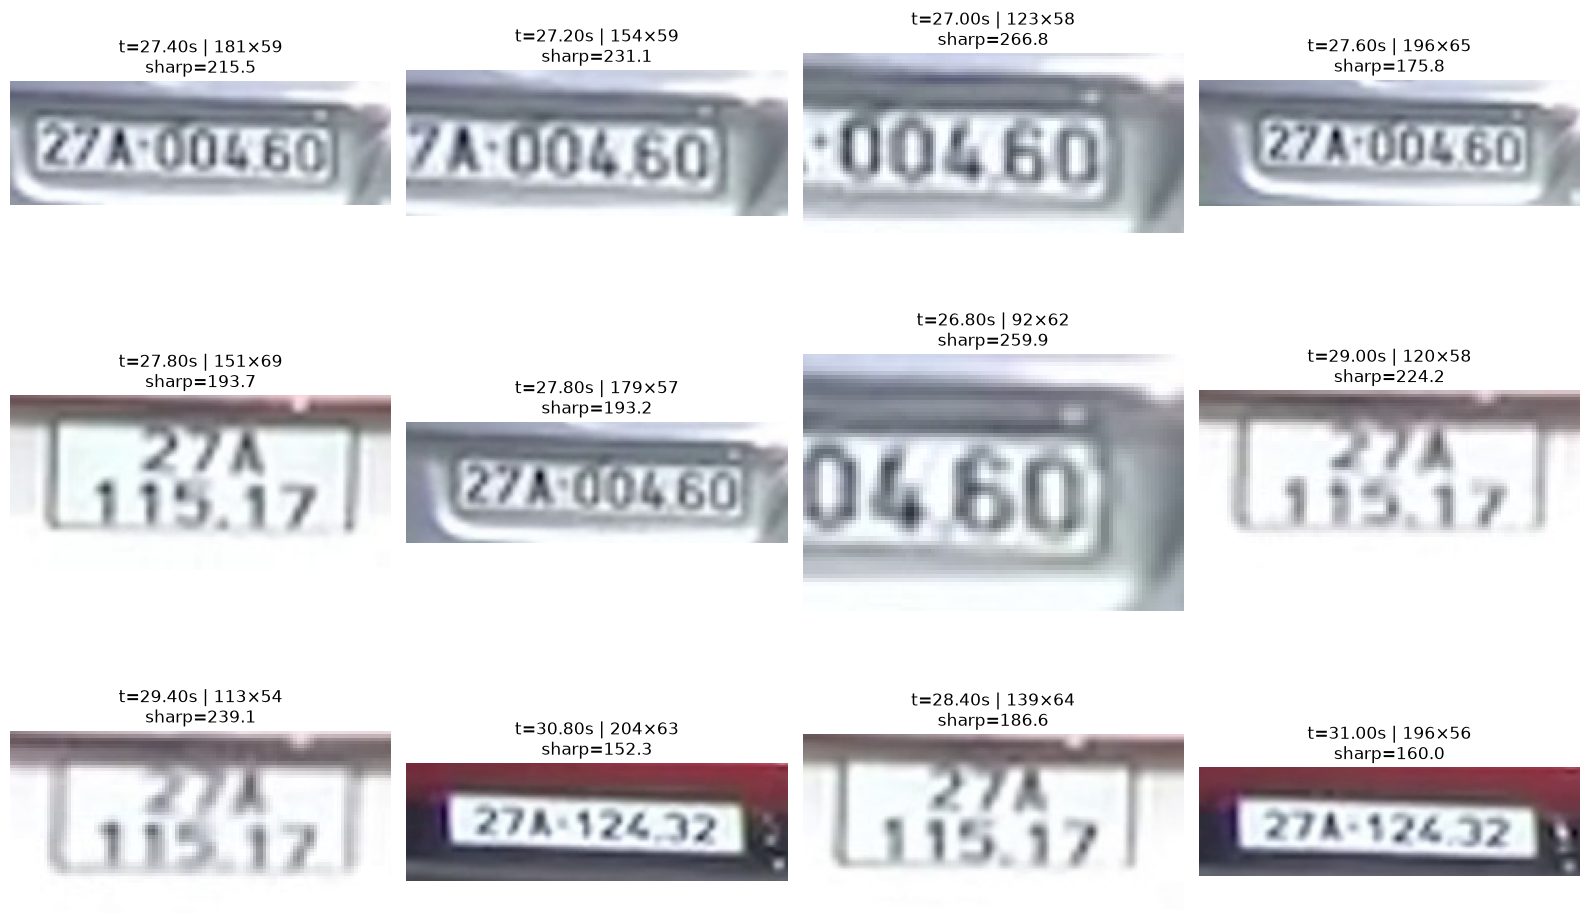

In [4]:
candidates_df["area_pixels"] = candidates_df.crop_width * candidates_df.crop_height
candidates_df["quality_rank_score"] = (
    np.log1p(candidates_df.area_pixels) * np.log1p(candidates_df.laplacian_variance.clip(lower=0))
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(candidates_df.area_pixels, candidates_df.laplacian_variance, alpha=.7)
axes[0].set(xlabel="Crop area (pixels)", ylabel="Laplacian variance", title="Size vs rough sharpness")
axes[1].hist(candidates_df.crop_height, bins=15)
axes[1].set(xlabel="Crop height (pixels)", title="Plate crop height")
axes[2].scatter(candidates_df.mean_brightness, candidates_df.contrast_std, alpha=.7)
axes[2].set(xlabel="Mean brightness", ylabel="Contrast standard deviation", title="Brightness vs contrast")
plt.tight_layout()
plt.show()

top_gallery = candidates_df.sort_values("quality_rank_score", ascending=False).head(12)

fig, axes = plt.subplots(max(1, int(np.ceil(len(top_gallery)/4))), 4, figsize=(16, 3.6*max(1, int(np.ceil(len(top_gallery)/4)))))

axes=np.array(axes).reshape(-1)
for ax, (_, row) in zip(axes, top_gallery.iterrows()):
    img=cv2.imread(row.crop_path)
    ax.imshow(cv2.cvtColor(img,cv2.COLOR_BGR2RGB))
    ax.axis("off")
    ax.set_title(f"t={row.timestamp_seconds:.2f}s | {row.crop_width}×{row.crop_height}\nsharp={row.laplacian_variance:.1f}")

for ax in axes[len(top_gallery):]: ax.axis("off")

plt.tight_layout()
plt.show()

## Select distinct frames for OCR

Avoid counting several nearly identical detections from adjacent frames as independent evidence. This selection keeps at most one crop per sampled frame and applies a minimum time gap. Review the gallery above and adjust the gap or top-N value if needed.

In [5]:
TOP_N_FRAMES = 8
MIN_FRAME_GAP_SECONDS = 0.40
ranked = candidates_df.sort_values("quality_rank_score", ascending=False)
selected_rows=[]

for _, row in ranked.iterrows():
    if all(abs(row.timestamp_seconds - old.timestamp_seconds) >= MIN_FRAME_GAP_SECONDS for old in selected_rows):
        selected_rows.append(row)
        
    if len(selected_rows) >= TOP_N_FRAMES: break

selected_df=pd.DataFrame(selected_rows).sort_values("timestamp_seconds").reset_index(drop=True)

display(selected_df[["frame_number","timestamp_seconds","detector_confidence","crop_width","crop_height","laplacian_variance","mean_brightness","contrast_std","crop_path"]])
print("Selected distinct-frame crops:",len(selected_df))

,frame_number,timestamp_seconds,detector_confidence,crop_width,crop_height,laplacian_variance,mean_brightness,contrast_std,crop_path
0,66,2.2,0.609297,98,75,196.186092,142.042585,65.105768,outputs\ranked_crops\frame_000002200_det_0.jpg
1,810,27.0,0.654369,123,58,266.768160,180.071348,46.821986,outputs\ranked_crops\frame_000027000_det_0.jpg
2,822,27.4,0.657024,181,59,215.517892,177.349565,45.154150,outputs\ranked_crops\frame_000027400_det_1.jpg
3,852,28.4,0.717241,139,64,186.581662,213.462905,53.393320,outputs\ranked_crops\frame_000028400_det_0.jpg
4,870,29.0,0.682601,120,58,224.191086,213.918678,52.288639,outputs\ranked_crops\frame_000029000_det_0.jpg
5,882,29.4,0.662726,113,54,239.127279,213.016224,51.208825,outputs\ranked_crops\frame_000029400_det_2.jpg
6,906,30.2,0.608942,97,54,244.876360,219.418289,48.243137,outputs\ranked_crops\frame_000030200_det_1.jpg
7,924,30.8,0.700412,204,63,152.308147,120.850062,67.632742,outputs\ranked_crops\frame_000030800_det_0.jpg


Selected distinct-frame crops: 8


## Compare conservative preprocessing and pretrained OCR

The original crop is retained. Upscaling is only a display/resampling operation; it cannot recreate missing character detail. CLAHE/grayscale/adaptive thresholding are comparisons, not guaranteed improvements. OCR is run on the selected frame crops, and the frame timestamp is preserved for the next notebook.

In [6]:
paddle_reader = PaddleOCR(use_angle_cls=True, lang="en")
easy_reader = easyocr.Reader(["en"], gpu=False)

def make_variants(crop):
    h,w=crop.shape[:2]
    scale=max(1.0, 160.0/max(h,1))
    
    enlarged=cv2.resize(crop,(int(w*scale),int(h*scale)),interpolation=cv2.INTER_CUBIC)
    lab=cv2.cvtColor(enlarged,cv2.COLOR_BGR2LAB); l,a,b=cv2.split(lab)
    clahe=cv2.createCLAHE(clipLimit=2.0,tileGridSize=(8,8))
    enhanced=cv2.cvtColor(cv2.merge((clahe.apply(l),a,b)),cv2.COLOR_LAB2BGR)
    gray=cv2.cvtColor(enhanced,cv2.COLOR_BGR2GRAY)
    denoised=cv2.bilateralFilter(gray,5,35,35)
    adaptive=cv2.adaptiveThreshold(denoised,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,cv2.THRESH_BINARY,31,11)
    
    return {"raw_upscaled":enlarged,"clahe":enhanced,"gray":gray,"adaptive":adaptive}

def normalize_text(value): return re.sub(r"[^A-Z0-9]","",str(value).upper())

def read_paddle(image):
    output=paddle_reader.ocr(image,cls=True)
    found=[]
    
    for group in output or []:
        for item in group or []:
            if len(item)>=2 and isinstance(item[1],(tuple,list)):
                txt=normalize_text(item[1][0]); conf=float(item[1][1])
                if txt: found.append((txt,conf))
    return found

def read_easy(image):
    output=easy_reader.readtext(image,detail=1,paragraph=False)
    return [(normalize_text(x[1]),float(x[2])) for x in output if len(x)>=3 and normalize_text(x[1])]

ocr_rows=[]
for _, row in selected_df.iterrows():
    original=cv2.imread(row.crop_path)
    for variant_name, image in make_variants(original).items():
        for engine_name, reader in (("PaddleOCR",read_paddle),("EasyOCR",read_easy)):
            started=time.perf_counter()
            
            try: predictions=reader(image)
            except Exception as exc:
                predictions=[]; print(f"{engine_name} failed: {exc}")
            
            latency=(time.perf_counter()-started)*1000
            
            # Preserve separate text detections instead of concatenating unrelated regions blindly.
            text="".join(p[0] for p in predictions)
            conf=float(np.mean([p[1] for p in predictions])) if predictions else 0.0
            ocr_rows.append({"frame_number":int(row.frame_number),"timestamp_seconds":float(row.timestamp_seconds),
                "crop_path":row.crop_path,"engine":engine_name,"variant":variant_name,
                "text":text,"confidence":conf,"latency_ms":latency,"num_text_regions":len(predictions)})

ocr_results=pd.DataFrame(ocr_rows)
display(ocr_results.sort_values(["engine","timestamp_seconds","confidence"],ascending=[True,True,False]).head(40))

ocr_results.to_csv(OUTPUT_DIR/"ocr_predictions_by_frame.csv",index=False)
candidates_df.to_csv(OUTPUT_DIR/"plate_crop_quality.csv",index=False)
selected_df.to_csv(OUTPUT_DIR/"selected_plate_frames.csv",index=False)
print("Saved experiment outputs to",OUTPUT_DIR.resolve())

Creating model: ('PP-LCNet_x1_0_doc_ori', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\Pasidu\.paddlex\official_models\PP-LCNet_x1_0_doc_ori`.
Creating model: ('UVDoc', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\Pasidu\.paddlex\official_models\UVDoc`.
Creating model: ('PP-LCNet_x1_0_textline_ori', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\Pasidu\.paddlex\official_models\PP-LCNet_x1_0_textline_ori`.
Creating model: ('PP-OCRv6_medium_det', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manually: `C:\Users\Pasidu\.paddlex\official_models\PP-OCRv6_medium_det`.
Creating model: ('PP-OCRv6_medium_rec', None, None)
Model files already exist. Using cached files. To redownload, please delete the directory manu

PaddleOCR failed: PaddleOCR.predict() got an unexpected keyword argument 'cls'
PaddleOCR failed: PaddleOCR.predict() got an unexpected keyword argument 'cls'
PaddleOCR failed: PaddleOCR.predict() got an unexpected keyword argument 'cls'
PaddleOCR failed: PaddleOCR.predict() got an unexpected keyword argument 'cls'
PaddleOCR failed: PaddleOCR.predict() got an unexpected keyword argument 'cls'
PaddleOCR failed: PaddleOCR.predict() got an unexpected keyword argument 'cls'
PaddleOCR failed: PaddleOCR.predict() got an unexpected keyword argument 'cls'
PaddleOCR failed: PaddleOCR.predict() got an unexpected keyword argument 'cls'
PaddleOCR failed: PaddleOCR.predict() got an unexpected keyword argument 'cls'
PaddleOCR failed: PaddleOCR.predict() got an unexpected keyword argument 'cls'
PaddleOCR failed: PaddleOCR.predict() got an unexpected keyword argument 'cls'
PaddleOCR failed: PaddleOCR.predict() got an unexpected keyword argument 'cls'
PaddleOCR failed: PaddleOCR.predict() got an unexpec

,frame_number,timestamp_seconds,crop_path,engine,variant,text,confidence,latency_ms,num_text_regions
3,66,2.2,outputs\ranked_crops\frame_000002200_det_0.jpg,EasyOCR,clahe,AJSL,0.248628,278.6995,2
7,66,2.2,outputs\ranked_crops\frame_000002200_det_0.jpg,EasyOCR,adaptive,N61JSRM,0.199618,202.9981,2
5,66,2.2,outputs\ranked_crops\frame_000002200_det_0.jpg,EasyOCR,gray,AJSLA,0.146175,240.6985,2
1,66,2.2,outputs\ranked_crops\frame_000002200_det_0.jpg,EasyOCR,raw_upscaled,,0.000000,168.3307,0
15,810,27.0,outputs\ranked_crops\frame_000027000_det_0.jpg,EasyOCR,adaptive,400LEO,0.481677,258.7067,1
9,810,27.0,outputs\ranked_crops\frame_000027000_det_0.jpg,EasyOCR,raw_upscaled,000460,0.355924,281.8242,1
11,810,27.0,outputs\ranked_crops\frame_000027000_det_0.jpg,EasyOCR,clahe,00460,0.138977,258.4016,1
13,810,27.0,outputs\ranked_crops\frame_000027000_det_0.jpg,EasyOCR,gray,00460,0.138977,255.0602,1
23,822,27.4,outputs\ranked_crops\frame_000027400_det_1.jpg,EasyOCR,adaptive,22000360,0.314141,339.5103,1
21,822,27.4,outputs\ranked_crops\frame_000027400_det_1.jpg,EasyOCR,gray,2ZA00560,0.126106,327.6431,1


Saved experiment outputs to C:\Users\Pasidu\OneDrive\Documents\Developments\AI\Projects\Assignments\motosignal-ai\notebooks\outputs


## Visualize OCR confidence and readable coverage

Confidence values are model-specific and are not calibrated probabilities. A non-empty string with low confidence is not automatically readable. Compare each prediction against the crop image and an independently verified ground-truth label where available.

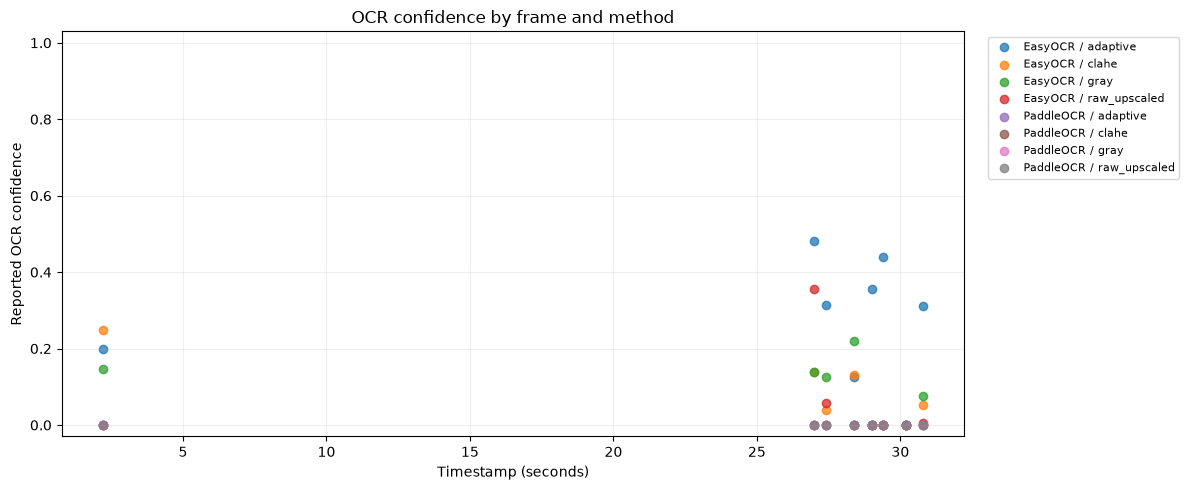

,engine,variant,readable
0,EasyOCR,adaptive,0.875
1,EasyOCR,clahe,0.625
2,EasyOCR,gray,0.625
3,EasyOCR,raw_upscaled,0.375
4,PaddleOCR,adaptive,0.000
5,PaddleOCR,clahe,0.000
6,PaddleOCR,gray,0.000
7,PaddleOCR,raw_upscaled,0.000


In [7]:
fig, ax=plt.subplots(figsize=(12,5))
plot_df=ocr_results.copy()
plot_df["label"]=plot_df.engine+" / "+plot_df.variant

for label, group in plot_df.groupby("label"):
    ax.scatter(group.timestamp_seconds,group.confidence,label=label,alpha=.75)

ax.set(xlabel="Timestamp (seconds)",ylabel="Reported OCR confidence",ylim=(-.03,1.03),title="OCR confidence by frame and method")
ax.legend(bbox_to_anchor=(1.02,1),loc="upper left",fontsize=8)
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

coverage=ocr_results.assign(readable=ocr_results.text.fillna("").str.len()>0).groupby(["engine","variant"]).readable.mean().reset_index()
display(coverage)